In [1]:
import pandas as  pd
import numpy as np

In [2]:
df = pd.read_excel("mart_product_info.xlsx")

In [ ]:
########## VIEW ATTRIBUTE ##########
cols = df.columns
print(cols)

Index(['product_id', 'brand', 'image_url', 'video_url', 'product_description',
       'product_specifications', 'product_details', 'sizes', 'breadcrumbs',
       'category', 'seller_index', 'currency_index', 'initial_price',
       'discount', 'final_price', 'apply_discount', 'delivery_options',
       'best_offer', 'more_offers', 'rating', 'ratings_count',
       'what_customers_said'],
      dtype='object')


In [4]:
############ CHECK AND DROP DUPLICATED SAMPLES BASE ON PRODUCT_ID ########
df['product_id'].duplicated().sum()

np.int64(0)

In [5]:
########### MISSING VALUE ####################
def is_null(x):
    # None / NaN
    if x is None:
        return 1

    if isinstance(x, (float, np.floating)) and pd.isna(x):
        return 1

    # empty string
    if x == "":
        return 1

    # empty dict
    if x == "{}":
        return 1

    # [{}]
    if x == "[{}]":
        return 1

    return 0
null_counts=(df[cols].map(is_null).sum())
print(null_counts[null_counts>0])



video_url              781
best_offer             306
what_customers_said    573
dtype: int64


video_url -> video_url_flag: type(binary)

best_offer -> further processing

what_customers_said -> drop

In [6]:
def clean_text(x):
    if pd.isna(x):
        return ""
    return str(x).strip().lower()

for col in cols:
    df[col] = df[col].apply(clean_text)

In [7]:
df[cols].nunique()

,0
product_id,1000
brand,454
image_url,1000
video_url,220
product_description,989
product_specifications,967
product_details,998
sizes,672
breadcrumbs,658
category,97


product_id -> drop

brand (Category) -> Mean target encoding

image_url -> num_images: type(numerical)

video_url -> num_videos: type(numerical)

product_description, product_specifications, product_details -> embeded

size -> sizes_count

breadcrumbs -> drop do trùng thông tin với category và brand

category -> OHE

drop seller_index: lỗi

drop currency_index: 1 giá trị

discount -> 0/%


354 components explain 90.04% variance


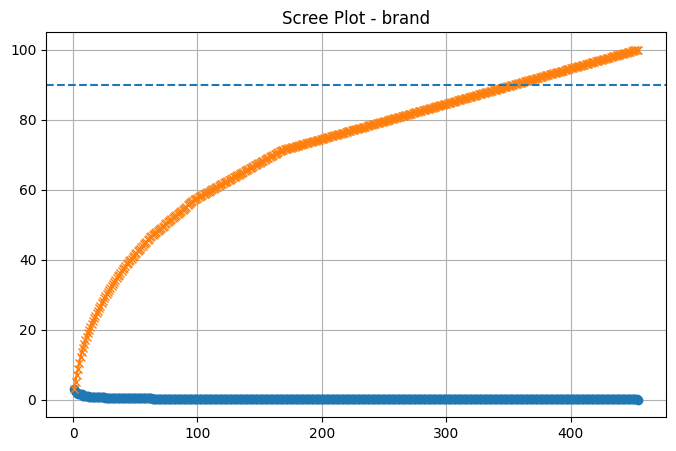

(PCA(n_components=np.int64(354)),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]))

In [8]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

def n_components(df, col, encoder, variance_threshold=0.9):
    encoded = encoder.fit_transform(df[[col]])

    # Fit full PCA
    pca_full = PCA().fit(encoded)

    explained_var = pca_full.explained_variance_ratio_
    cumulative_var = np.cumsum(explained_var)

    # tìm số components
    n_comps = np.argmax(cumulative_var >= variance_threshold) + 1

    print(f"{n_comps} components explain {cumulative_var[n_comps-1]*100:.2f}% variance")

    # plot
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(explained_var)+1), explained_var*100, marker='o')
    plt.plot(range(1, len(cumulative_var)+1), cumulative_var*100, marker='x')
    plt.axhline(variance_threshold*100, linestyle='--')
    plt.grid(True)
    plt.title(f"Scree Plot - {col}")
    plt.show()

    # PCA final model
    pca_model = PCA(n_components=n_comps).fit(encoded)

    return pca_model, encoded
OHEncoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
n_components(df, 'brand', OHEncoder, 0.9)

number of category to explain 90% information is to high

In [9]:
print(df['brand'].value_counts())
brand_counts = df['brand'].value_counts()
print(f"Number of brand appear 1 time: {brand_counts[brand_counts==1].sum()}")


brand
roadster           30
u.s. polo assn.    22
levis              21
mast & harbour     17
flying machine     17
                   ..
soie                1
erotissch           1
tweens              1
shyaway             1
zinu                1
Name: count, Length: 454, dtype: int64
Number of brand appear 1 time: 286


Số lượng brand chỉ xuất hiện 1 lần lớn -> smooth

In [10]:
from sklearn.preprocessing import TargetEncoder

TGencoder = TargetEncoder(
    smooth=True,
    target_type="continuous"
)

df['brand_encoded'] = TGencoder.fit_transform(df[['brand']], df['rating'])

In [11]:
def count_by_split_on_comma(x):
  if pd.isna(x) or x=="":
    return 0
  return len(x.split(','))
df['image_url'].apply(count_by_split_on_comma).value_counts()

,count
image_url,
5,359
6,286
7,197
4,68
8,38
3,35
9,11
10,4
2,1


In [12]:
df['images_count']=df['image_url'].apply(count_by_split_on_comma)

In [13]:
print(df['video_url'].apply(count_by_split_on_comma).value_counts())
df['videos_count']=df['video_url'].apply(count_by_split_on_comma)

video_url
0    781
1    146
2     56
3     17
Name: count, dtype: int64


In [14]:
import json
def count_object_in_array(x):
  if pd.isna(x) or x=="":
    return 0
  if isinstance(x, str):
    x=json.loads(x)
  return len(x)
df['sizes'].apply(count_object_in_array).value_counts()

,count
sizes,
1,174
15,120
12,97
20,62
6,61
18,61
16,59
5,51
24,47


In [15]:
print(len(df['sizes'].apply(count_object_in_array).value_counts()))
df['sizes_count']=df['sizes'].apply(count_object_in_array)


42


36 components explain 90.29% variance


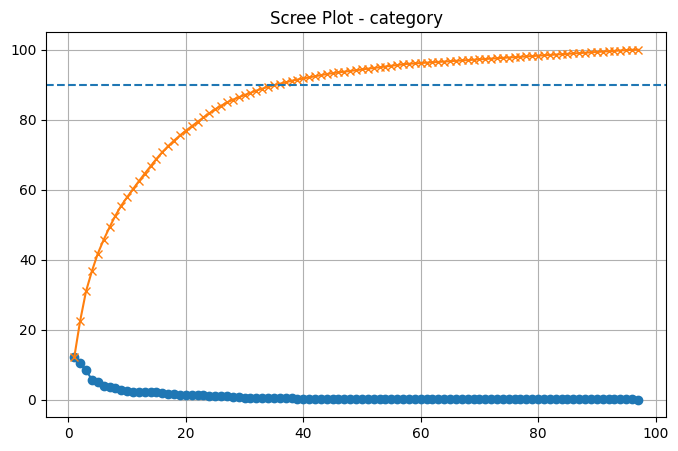

In [16]:
category_pca_model, category_encoded = n_components(df, 'category', OHEncoder, 0.9)
X_pca = category_pca_model.transform(category_encoded)
pca_cols = [f'category_pca_{i}' for i in range(X_pca.shape[1])]
df[pca_cols] = X_pca

In [17]:
df['apply_discount'].value_counts()
df['apply_discount'] = (
    df['apply_discount']
    .map({
        'true': 1,
        'false': 0
    })
)
df['apply_discount'].value_counts()
def discount_percent(discount, apply_discount):
  if apply_discount == 1:
    return discount
  return 0

df['discount'] = df.apply(lambda x: discount_percent(x['discount'], x['apply_discount']), axis=1)
df['discount'].head()

,discount
0,0
1,0
2,0
3,0
4,0


In [18]:
import ast
from collections import Counter

def extract_delivery_option(df):
    delivery_options = df['delivery_options']

    # convert string -> list
    parsed_options = delivery_options.apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else []
    )

    # đếm tổng các option
    counter = Counter()

    for options in parsed_options:
        counter.update(options)

    # convert thành dataframe
    option_count_df = (
        pd.DataFrame(
            counter.items(),
            columns=['delivery_option', 'count']
        )
        .sort_values(by='count', ascending=False)
        .reset_index(drop=True)
    )

    return option_count_df

extract_delivery_option(df)

,delivery_option,count
0,100% original products,1000
1,pay on delivery might be available,997
2,try & buy might be available,798
3,easy 14 days returns and exchanges,767
4,easy 7 days returns and exchanges,161
5,"items like innerwear, socks, certain accessori...",27
6,this item is only returnable and not exchangeable,16
7,easy 14 days returns,16
8,this item is only exchangeable for the same or...,10
9,easy 14 days exchanges,10


In [19]:
import re

import ast

def normalize_options(options):

    # null
    if options is None:
        return []

    # string list -> python list
    if isinstance(options, str):
        try:
            options = ast.literal_eval(options)
        except:
            return []

    # đảm bảo list
    if not isinstance(options, list):
        return []

    return [str(x).lower().strip() for x in options]

def parse_delivery_options(options):
    options = normalize_options(options)

    features = {
        "original_product": 0,
        "pay_on_delivery": 0,
        "try_and_buy": 0,

        "returnable": 0,
        "exchangeable": 0,

        "return_days": 0,
        "exchange_days": 0,

        "restricted_return": 0,
        "size_exchange_only": 0,
    }

    text = " ".join(options).lower()

    # 100% original product
    if "original products" in text:
        features["original_product"] = 1

    # pay on delivery might be available
    if "pay on delivery might be available" in text:
        features["pay_on_delivery"] = 1
    # # pay on delivery is not available
    # if "pay on delivery is not available" in text:
    #     features["pay_on_delivery"] = 0


    # try & buy might be available
    if "try & buy might be available" in text:
        features["try_and_buy"] = 1

    # items like innerwear, socks, certain accessories and some high-value fragile items do not come under our return policy
    if "do not come under our return policy" in text:
        features["restricted_return"] = 1
        # features["returnable"] = 0
        # features["exchangeable"] = 0

    # this item is only returnable and not exchangeable
    if "only returnable and not exchangeable" in text:
        features["returnable"] = 1
        # features["exchangeable"] = 0

    #8	this item is only exchangeable for the same or a different size, if available, and cannot be returned
    if "this item is only exchangeable for the same or a different size, if available, and cannot be returned" in text:
        features["size_exchange_only"] = 1
        # features["returnable"] = 0
        features["exchangeable"] = 1

    # extract days
    # easy 14 days returns and exchanges
    # easy 7 days returns and exchanges	161
    # easy 14 days returns
    # easy 14 days exchanges
    # easy 21 days returns and exchanges
    # easy 2 days returns and exchanges
    # easy 30 days returns and exchanges
    # easy 15 days returns and exchanges
    # easy 10 days returns and exchanges
    match = re.findall(r'(\d+)\s*days', text)

    if match:
        days = max(map(int, match))

        if "returns and exchanges" in text:
            features["returnable"] = 1
            features["return_days"] = days
            features["exchangeable"] = 1
            features["exchange_days"] = days

        elif "easy 14 days returns" in text:
            features["returnable"] = 1
            features["return_days"] = 14
        elif "easy 14 days exchanges" in text:
            features["exchangeable"] = 1
            features["exchange_days"] = 14

    return features

delivery_features = df['delivery_options'].apply(parse_delivery_options)

delivery_df = pd.DataFrame(delivery_features.tolist())
print(delivery_df.value_counts())

df = pd.concat([df, delivery_df], axis=1)

original_product  pay_on_delivery  try_and_buy  returnable  exchangeable  return_days  exchange_days  restricted_return  size_exchange_only
1                 1                1            1           1             14           14             0                  0                     650
                                                                          7            7              0                  0                     132
                                   0            1           1             14           14             0                  0                     117
                                                0           0             0            0              1                  0                      26
                                                1           1             7            7              0                  0                      26
                                                            0             14           0              0                  0   

In [20]:
import ast
import pandas as pd
import numpy as np

def extract_best_offer(
    df,
    final_price_col,
    best_offer_col,
    target_col='best_price'
):

    def parse_best_price(value, final_price):

        # null
        if pd.isna(value):
            return np.nan, 0

        # string -> dict
        if isinstance(value, str):
            try:
                value = ast.literal_eval(value)
            except:
                return np.nan, 0

        # phải là dict
        if not isinstance(value, dict):
            return np.nan, 0

        # empty dict
        if len(value) == 0:
            return float(final_price), 0

        # có best offer
        has_best_offer = 1

        # không có best_price
        if 'best_price' not in value:
            return float(final_price), has_best_offer

        best_price = value.get('best_price')

        # convert numeric
        try:
            best_price = str(best_price).replace(',', '').strip()
            return float(best_price), has_best_offer

        except:
            return np.nan, has_best_offer

    parsed = df.apply(
        lambda row: parse_best_price(
            row[best_offer_col],
            row[final_price_col]
        ),
        axis=1
    )

    # tách tuple
    df[target_col] = parsed.apply(lambda x: x[0])
    df['has_best_offer'] = parsed.apply(lambda x: x[1])

    return df
df = extract_best_offer(
    df,
    final_price_col='final_price',
    best_offer_col='best_offer'
)

In [21]:
df.head(10)

,product_id,brand,image_url,video_url,product_description,product_specifications,product_details,sizes,breadcrumbs,category,...,pay_on_delivery,try_and_buy,returnable,exchangeable,return_days,exchange_days,restricted_return,size_exchange_only,best_price,has_best_offer
0,8376765,lino perros,http://assets.myntassets.com/assets/images/837...,"[""rw-8376765_cae700""]",women navy blue solid backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""navy blue solid backpacknon-pa...","[{""size"":""onesize""}]","[{""name"":""accessories"",""url"":""https://www.mynt...",backpacks,...,1,1,1,1,14,14,0,0,3995.0,0
1,9136281,tommy hilfiger,http://assets.myntassets.com/assets/images/913...,"[""rw-9136281_cae700""]",unisex navy blue striped backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""navy blue backpacknon-padded h...","[{""size"":""onesize""}]","[{""name"":""accessories"",""url"":""https://www.mynt...",backpacks,...,1,1,1,1,14,14,0,0,2899.0,0
2,17633752,lavie,http://assets.myntassets.com/assets/images/176...,"[""https://videos.myntassets.com/assets/videos/...",aries women pink mini backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""pink solid backpacks non-padd...","[{""size"":""s""}]","[{""name"":""accessories"",""url"":""https://www.mynt...",backpacks,...,1,1,1,1,14,14,0,0,2999.0,0
3,1376949,f gear,http://assets.myntassets.com/assets/images/137...,"[""https://videos.myntassets.com/assets/videos/...",unisex navy & grey printed burner backpack,"[{""specification_name"":""compartment closure"",""...","{""description"":""navy and grey printed backpack...","[{""size"":""onesize""}]","[{""name"":""accessories"",""url"":""https://www.mynt...",backpacks,...,1,1,1,1,14,14,0,0,1675.0,0
4,13939916,mytrident,http://assets.myntassets.com/assets/images/pro...,,men blue solid bath robe,"[{""specification_name"":""body or garment size"",...","{""description"":""blue solid bath robe, has a sh...","[{""size"":""m"",""value"":""45.0in"",""value_name"":""fr...","[{""name"":""men"",""url"":""https://www.myntra.com/m...",bath-robe,...,1,1,1,1,14,14,0,0,2899.0,0
5,19851824,avi living,http://assets.myntassets.com/assets/images/198...,,grey solid 500 gsm pure cotton bath towel,"[{""specification_name"":""fabric"",""specification...","{""description"":""set content: 1 bath towelfeatu...","[{""size"":""onesize""}]","[{""name"":""unisex"",""url"":""https://www.myntra.co...",bath-towels,...,1,1,1,1,14,14,0,0,1399.0,0
6,17198778,h&m,http://assets.myntassets.com/assets/images/171...,,beige & tan solid stoneware soap dispenser,"[{""specification_name"":""finish"",""specification...","{""description"":""soap dispenser in glazed stone...","[{""size"":""onesize""}]","[{""name"":""unisex"",""url"":""https://www.myntra.co...",bathroom-accessories,...,1,0,1,1,14,14,0,0,1026.0,1
7,18602872,my room,http://assets.myntassets.com/assets/images/186...,,yellow & green floral 140 tc king bedsheet wit...,"[{""specification_name"":""bed size"",""specificati...","{""description"":""set content: 1 king bedsheet w...","[{""size"":""single""},{""size"":""double queen""},{""s...","[{""name"":""unisex"",""url"":""https://www.myntra.co...",bedsheets,...,1,0,1,1,14,14,0,0,2999.0,0
8,18602850,my room,http://assets.myntassets.com/assets/images/186...,,ethnic print 144 tc super king bedsheet with 2...,"[{""specification_name"":""bed size"",""specificati...","{""description"":""dimensions: super king bedshee...","[{""size"":""super king""}]","[{""name"":""unisex"",""url"":""https://www.myntra.co...",bedsheets,...,1,0,1,1,14,14,0,0,2999.0,0
9,8961147,story@home,http://assets.myntassets.com/assets/images/896...,,pink & white floral 160 tc cotton 1 king bedsh...,"[{""specification_name"":""bed size"",""specificati...","{""description"":""set content: 1 king bedsheet w...","[{""size"":""double king""}]","[{""name"":""unisex"",""url"":""https://www.myntra.co...",bedsheets,...,1,0,1,1,14,14,0,0,2199.0,

In [22]:
import ast
import pandas as pd
from collections import Counter

def count_offer_from_more_offers(df, col='more_offers'):

    counter = Counter()

    offer_counts_per_row = []

    for value in df[col]:

        # null
        if pd.isna(value):
            offer_counts_per_row.append(0)
            continue

        # string -> python object
        if isinstance(value, str):
            try:
                value = ast.literal_eval(value)
            except:
                offer_counts_per_row.append(0)
                continue

        # phải là list
        if not isinstance(value, list):
            offer_counts_per_row.append(0)
            continue

        # số lượng offers trong row
        offer_counts_per_row.append(len(value))

        for item in value:

            # mỗi item phải là dict
            if not isinstance(item, dict):
                continue

            offer_name = item.get('offer_name')

            if offer_name:
                counter.update([offer_name.strip().lower()])

    # thêm cột mới
    df['more_offers_count'] = offer_counts_per_row

    # convert dataframe frequency
    result = (
        pd.DataFrame(
            counter.items(),
            columns=['offer_name', 'count']
        )
        .sort_values(by='count', ascending=False)
        .reset_index(drop=True)
    )

    return df, result

df, offer_counts = count_offer_from_more_offers(df)

print(offer_counts)

                                          offer_name  count
0  10% instant discount on citi credit & debit cards   1000
1  10% instant discount on indusind bank debit cards    673
2          flat ₹100 cashback on mobiwkik wallet/zip    673
3      10% instant discount on yes bank credit cards    673
4         7.5% discount on myntra kotak credit card.    673
5                               emi option available    596


In [23]:
import ast
import pandas as pd

def extract_offer_features(df, col='more_offers'):

    features = []

    for value in df[col]:

        row = {
            'emi_available': 0,
            'citi_offer': 0,
            'indusind_offer': 0,
            'cashback_offer': 0,
            'yes_bank_offer': 0,
            'myntra_kotak_offer': 0,
        }

        # null
        if pd.isna(value):
            features.append(row)
            continue

        # string -> list
        if isinstance(value, str):
            try:
                value = ast.literal_eval(value)
            except:
                features.append(row)
                continue

        if not isinstance(value, list):
            features.append(row)
            continue

        for item in value:

            if not isinstance(item, dict):
                continue

            offer_name = str(
                item.get('offer_name', '')
            ).lower()

            # semantic features
            if 'emi' in offer_name:
                row['emi_available'] = 1

            if 'cashback' in offer_name:
                row['cashback_offer'] = 1

            if 'citi' in offer_name:
                row['credit_card_offer'] = 1

            if 'indusind' in offer_name:
                row['indusind_offer'] = 1

            if 'yes bank' in offer_name:
                row['yes_bank_offer'] = 1

            if 'myntra' in offer_name:
                row['myntra_kotak_offer'] = 1

        features.append(row)

    feature_df = pd.DataFrame(features, index=df.index)

    df = pd.concat([df, feature_df], axis=1)

    return df
df = extract_offer_features(df)

In [24]:
df.columns

Index(['product_id', 'brand', 'image_url', 'video_url', 'product_description',
       'product_specifications', 'product_details', 'sizes', 'breadcrumbs',
       'category', 'seller_index', 'currency_index', 'initial_price',
       'discount', 'final_price', 'apply_discount', 'delivery_options',
       'best_offer', 'more_offers', 'rating', 'ratings_count',
       'what_customers_said', 'brand_encoded', 'images_count', 'videos_count',
       'sizes_count', 'category_pca_0', 'category_pca_1', 'category_pca_2',
       'category_pca_3', 'category_pca_4', 'category_pca_5', 'category_pca_6',
       'category_pca_7', 'category_pca_8', 'category_pca_9', 'category_pca_10',
       'category_pca_11', 'category_pca_12', 'category_pca_13',
       'category_pca_14', 'category_pca_15', 'category_pca_16',
       'category_pca_17', 'category_pca_18', 'category_pca_19',
       'category_pca_20', 'category_pca_21', 'category_pca_22',
       'category_pca_23', 'category_pca_24', 'category_pca_25',
      

In [25]:
def drop_cols(df, cols):
    return df.drop(cols, axis=1)
drop_colums = [
    'product_id',
    'brand',
    'image_url',
    'video_url',
    'sizes',
    'breadcrumbs',
    'category',
    'seller_index',
    'currency_index',
    'apply_discount',
    'delivery_options',
    'best_offer',
    'more_offers',
    'what_customers_said',
    'ratings_count'
]
df = drop_cols(df, drop_colums)
df.head()




,product_description,product_specifications,product_details,initial_price,discount,final_price,rating,brand_encoded,images_count,videos_count,...,best_price,has_best_offer,more_offers_count,emi_available,citi_offer,indusind_offer,cashback_offer,yes_bank_offer,myntra_kotak_offer,credit_card_offer
0,women navy blue solid backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""navy blue solid backpacknon-pa...",3995,0,3995,3.8,3.947625,6,1,...,3995.0,0,2,1,0,0,0,0,0,1
1,unisex navy blue striped backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""navy blue backpacknon-padded h...",2899,0,2899,4.5,4.332937,8,1,...,2899.0,0,2,1,0,0,0,0,0,1
2,aries women pink mini backpack,"[{""specification_name"":""add-ons"",""specificatio...","{""description"":""pink solid backpacks non-padd...",2999,0,2999,4.4,4.007125,8,1,...,2999.0,0,2,1,0,0,0,0,0,1
3,unisex navy & grey printed burner backpack,"[{""specification_name"":""compartment closure"",""...","{""description"":""navy and grey printed backpack...",1675,0,1675,4.4,3.656000,4,2,...,1675.0,0,2,1,0,0,0,0,0,1
4,men blue solid bath robe,"[{""specification_name"":""body or garment size"",...","{""description"":""blue solid bath robe, has a sh...",2899,0,2899,4.7,4.028000,5,0,...,2899.0,0,5,0,0,1,1,1,1,1


In [26]:
def build_text(row):
    return f"""
    Description: {row['product_description']}
    Specifications: {row['product_specifications']}
    Details: {row['product_details']}
    """
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer('all-MiniLM-L6-v2')

texts = df.apply(build_text, axis=1).tolist()
embeddings = embedder.encode(texts, show_progress_bar=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

In [27]:
other_cols = df.columns.difference(
    [
        'product_description',
        'product_specifications',
        'product_details'
    ]
)
other_features = df[other_cols].values

In [28]:
import numpy as np

X = np.hstack([embeddings, other_features])
y = df['rating'].values

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [30]:
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

preds = model.predict(X_test)

mse = mean_squared_error(y_test, preds)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, preds)

print("RMSE:", rmse)
print("MAE:", mae)

RMSE: 0.21349484329618212
MAE: 0.12496089935302734


In [32]:
# new_product = {
#     "brand": "Adidas",
#     "category": "Shoes",
#     "product_description": "Lightweight sneakers for running",
#     "product_specifications": "Foam sole, breathable fabric",
#     "product_details": "Comfortable and stylish",
#     "sizes": "39,40,41",
#     "initial_price": 150,
#     "final_price": 120,
#     "discount": 20,
#     "apply_discount": 1,
#     "ratings_count": 1500,
#     "delivery_options": "Express",
#     "best_offer": "Free shipping",
#     "more_offers": "5% bank discount",
#     "video_url_flag": 1,
#     "seller_index": 12
# }

# new_df = pd.DataFrame([new_product])

# # Build text
# new_text = new_df.apply(build_text, axis=1).tolist()

# # Embedding
# new_embedding = embedder.encode(new_text)

# # Numerical features
# new_num_features = new_df[[
#     'initial_price',
#     'final_price',
#     'discount',
#     'ratings_count',
#     'seller_index',
#     'video_url_flag'
# ]].values

# # Combine
# new_X = np.hstack([new_embedding, new_num_features])

# # Predict
# predicted_rating = model.predict(new_X)[0]

# print("\n===== NEW PRODUCT PREDICTION =====")
# print(f"Predicted Rating: {predicted_rating:.2f}")